# Handwritten Digit Classification Using Random Forests

## Objective
The goal of this project is to train a machine-learning model that recognises handwritten digits from images.

## Dataset
This project uses scikit-learn's built-in handwritten digits dataset. It contains 1,797 images, each represented by 64 numerical pixel features from an 8×8 image. The target labels are the digits 0–9.

## Approach
1. Explore and visualise the dataset.
2. Split the data into training and test sets.
3. Train a Random Forest classifier.
4. Use cross-validation to select model settings.
5. Evaluate the final model using classification metrics and a confusion matrix.

In [1]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load dataset
from sklearn.datasets import load_digits

# Split data and tune model
from sklearn.model_selection import train_test_split, GridSearchCV

# Machine learning model
from sklearn.ensemble import RandomForestClassifier

# Evaluate model performance
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

digits = load_digits()

## 1. Exploring the Dataset

Before training the model, it is useful to inspect the dataset and understand its structure.

The feature data contains the numerical pixel values used by the model, while the target data contains the correct digit labels. Visualising a few images helps us understand what the model is learning to classify.

The dataset shape also tells us how many images and features are available.

Image data shape: (1797, 64)
Label data shape: (1797,)
Digit classes: [0 1 2 3 4 5 6 7 8 9]


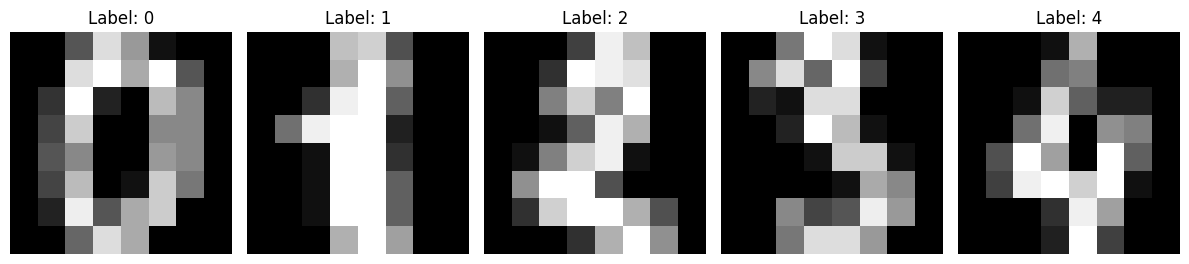

In [2]:
X = digits.data
y = digits.target

print("Image data shape:", X.shape)
print("Label data shape:", y.shape)
print("Digit classes:", np.unique(y))

fig, axes = plt.subplots(1, 5, figsize=(12, 3))

for index, ax in enumerate(axes):
    ax.imshow(digits.images[index], cmap="gray")
    ax.set_title(f"Label: {y[index]}")
    ax.axis("off")

plt.tight_layout()
plt.show()

## 2. Splitting the Data

I split the dataset into training and test sets, using 80% of the data to train the model and the remaining 20% to test how well it performs on images it hasn't seen before.

I used a fixed random state so I can get the same split each time I run the code. I also used stratification to keep the distribution of digit labels similar in both sets.

Keeping the test data separate helps me get a more realistic idea of how well the model performs on new data.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Test samples:", len(X_test))

Training samples: 1437
Test samples: 360


## 3. Training and Selecting the Model

A Random Forest is a machine-learning algorithm that combines predictions from multiple decision trees to make a final prediction. It can be used for classification tasks such as recognising handwritten digits.

The model's performance can depend on its settings, known as hyperparameters. This project compares different values for `max_depth`, which controls the maximum depth of each tree, and `n_estimators`, which determines the number of trees in the forest.

Five-fold cross-validation is used to compare these configurations on the training data. The training data is divided into five folds, and each fold is used for validation in turn while the remaining folds are used for training.

The configuration with the best average cross-validation accuracy is selected. The test set is not used to choose the model settings.

In [4]:
param_grid = {
    "max_depth": [None, 2, 3, 4, 5, 6, 7, 10],
    "n_estimators": [100, 200]
}

grid_search = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

best_model = grid_search.best_estimator_

print("Best parameters:", grid_search.best_params_)
print(
    "Best cross-validation accuracy:",
    round(grid_search.best_score_, 4)
)


Best parameters: {'max_depth': 10, 'n_estimators': 200}
Best cross-validation accuracy: 0.9756


## 4. Evaluating the Model

After selecting the model configuration using cross-validation, the model is evaluated on the held-out test set.

Several metrics are used to assess its performance:

- **Accuracy:** the proportion of all test images classified correctly.
- **Precision:** how often predictions for a particular digit are correct.
- **Recall:** the proportion of actual examples of a digit that the model correctly identifies.
- **F1-score:** a measure that combines precision and recall.

Precision, recall and F1-score are calculated using macro averaging, which gives each digit class equal weight when calculating the overall score.

Using several metrics provides a more complete picture of the model's performance than accuracy alone.

In [5]:
preds = best_model.predict(X_test)

print("Test accuracy:", round(accuracy_score(y_test, preds), 4))
print("Macro precision:", round(precision_score(y_test, preds, average="macro"), 4))
print("Macro recall:", round(recall_score(y_test, preds, average="macro"), 4))
print("Macro F1-score:", round(f1_score(y_test, preds, average="macro"), 4))

print("\nClassification report:")
print(classification_report(y_test, preds))


Test accuracy: 0.9639
Macro precision: 0.9647
Macro recall: 0.9636
Macro F1-score: 0.9635

Classification report:
              precision    recall  f1-score   support

           0       1.00      0.97      0.99        36
           1       0.90      0.97      0.93        36
           2       1.00      1.00      1.00        35
           3       0.97      0.97      0.97        37
           4       0.97      0.97      0.97        36
           5       0.97      1.00      0.99        37
           6       1.00      0.97      0.99        36
           7       0.92      1.00      0.96        36
           8       0.94      0.86      0.90        35
           9       0.97      0.92      0.94        36

    accuracy                           0.96       360
   macro avg       0.96      0.96      0.96       360
weighted avg       0.96      0.96      0.96       360



The training set is used to train the model.
The test set is used to evaluate how well the model performs on unseen data.

### Create classification model and tune max_depth parameter

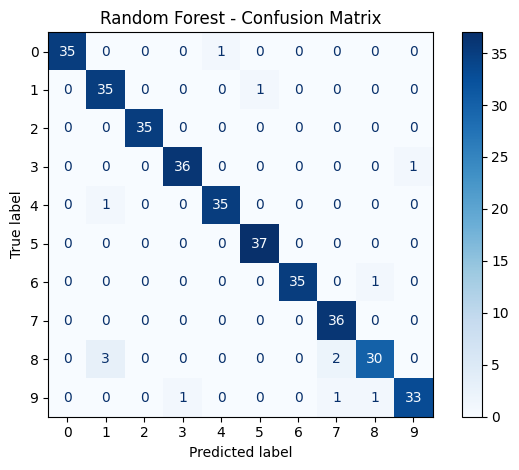

In [6]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    preds,
    cmap="Blues",
    values_format="d"
)

plt.title("Random Forest - Confusion Matrix")
plt.tight_layout()
plt.show()

## Conclusion  
This project gave me practical experience with training and evaluating a machine learning model for digit classification. I used cross-validation to compare different Random Forest configurations and evaluated the selected model on a separate test set.

The model achieved a test accuracy of 0.9639%. One limitation is that the dataset contains small, 8×8 pixel images, so the results may not reflect how well the model would perform on real-world handwritten images.